# 🌍 Global Economic & Demographic Insights (GEDI)
**Analisis Prediktif Tren Ekonomi & Demografi Global Berbasis Data World Bank**

## 📌 Pertanyaan

1. **Basic (1)**: Negara mana saja yang menduduki peringkat 10 besar dengan rata-rata GDP tertinggi dalam rentang data yang tersedia?
2. **Data Analyst (1)**: Bagaimana persentase persebaran negara-negara di dunia berdasarkan tingkat pendapatannya (*Income Level*)?
3. **Data Analyst (2)**: Apakah ada korelasi yang signifikan antara besaran Populasi dengan tingginya nilai GDP secara global?
4. **Data Analyst (3) / Spasial**: Bagaimana persebaran total populasi global jika divisualisasikan menggunakan peta dunia (*Geospatial*)?
5. **AI / Machine Learning (1)**: Berdasarkan tren historis, bagaimana prediksi/estimasi nilai GDP suatu negara (misalnya Indonesia) di masa depan menggunakan model Linear Regression?


### Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings
# Library untuk Machine Learning (Linear Regression)
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")


## 1. Data Loading (Memuat Data)
Pada tahap ini, kita akan membaca hasil ekstraksi data (ETL) yang sebelumnya telah disimpan ke dalam *Database* MySQL dan diekspor ke dalam bentuk CSV. Terdapat 3 tabel utama


In [2]:
# Membaca data langsung dari file CSV yang sudah di-upload
try:
    dim_country = pd.read_csv("dim_country.csv")
    dim_indicator = pd.read_csv("dim_indicator.csv")
    fact_data = pd.read_csv("fact_worldbank_data.csv")
    print("✅ Berhasil memuat data dari file CSV!")
except FileNotFoundError as e:
    print(f"❌ Gagal memuat data: {e}")



✅ Berhasil memuat data dari file CSV!


In [3]:
print("=== INFORMASI TABEL FACT_WORLDBANK_DATA (RAW) ===")
display(fact_data.info())
print("\nMissing Values:\n", fact_data.isnull().sum())
print("\nDuplikat:", fact_data.duplicated().sum())


=== INFORMASI TABEL FACT_WORLDBANK_DATA (RAW) ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5092 entries, 0 to 5091
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              5092 non-null   int64  
 1   country_code    5092 non-null   object 
 2   indicator_code  5092 non-null   object 
 3   year            5092 non-null   int64  
 4   value           5092 non-null   float64
dtypes: float64(1), int64(2), object(2)
memory usage: 199.0+ KB


None


Missing Values:
 id                0
country_code      0
indicator_code    0
year              0
value             0
dtype: int64

Duplikat: 0


##   2. Assessing Data (Pemeriksaan Data Mentah)
Sebelum melakukan analisis, kita harus mengecek karakteristik data mentah (tipe data, jumlah baris, *missing values*, dan duplikasi) dari masing-masing tabel untuk menentukan langkah pembersihan (*cleaning*) apa yang diperlukan.


In [4]:
print("=== 1. INFORMASI TABEL DIM_COUNTRY ===")
display(dim_country.info())
print("\nMissing Values:\n", dim_country.isnull().sum())
print("\nDuplikat:", dim_country.duplicated().sum())
print("-" * 50)

print("\n=== 2. INFORMASI TABEL DIM_INDICATOR ===")
display(dim_indicator.info())
print("\nMissing Values:\n", dim_indicator.isnull().sum())
print("\nDuplikat:", dim_indicator.duplicated().sum())
print("-" * 50)

print("\n=== 3. INFORMASI TABEL FACT_WORLDBANK_DATA ===")
display(fact_data.info())
print("\nMissing Values:\n", fact_data.isnull().sum())
print("\nDuplikat:", fact_data.duplicated().sum())


=== 1. INFORMASI TABEL DIM_COUNTRY ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 217 entries, 0 to 216
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   country_code  217 non-null    object
 1   country_name  217 non-null    object
 2   region        217 non-null    object
 3   income_level  217 non-null    object
dtypes: object(4)
memory usage: 6.9+ KB


None


Missing Values:
 country_code    0
country_name    0
region          0
income_level    0
dtype: int64

Duplikat: 0
--------------------------------------------------

=== 2. INFORMASI TABEL DIM_INDICATOR ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   indicator_code  2 non-null      object
 1   indicator_name  2 non-null      object
 2   source_note     2 non-null      object
dtypes: object(3)
memory usage: 180.0+ bytes


None


Missing Values:
 indicator_code    0
indicator_name    0
source_note       0
dtype: int64

Duplikat: 0
--------------------------------------------------

=== 3. INFORMASI TABEL FACT_WORLDBANK_DATA ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5092 entries, 0 to 5091
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              5092 non-null   int64  
 1   country_code    5092 non-null   object 
 2   indicator_code  5092 non-null   object 
 3   year            5092 non-null   int64  
 4   value           5092 non-null   float64
dtypes: float64(1), int64(2), object(2)
memory usage: 199.0+ KB


None


Missing Values:
 id                0
country_code      0
indicator_code    0
year              0
value             0
dtype: int64

Duplikat: 0


#  3. Data Cleaning & Feature Engineering
Dari hasil *assessing* di atas, kita akan melakukan langkah-langkah pembersihan:
1. Menghapus karakter spasi berlebih pada kolom teks (*strip*).
2. Membuang data fakta yang nilainya (*value*) kosong.
3. Melakukan **Pivot Table** pada data fakta agar metrik `GDP` dan `Population` memiliki kolomnya masing-masing.
4. Menggabungkan (*Merge*) tabel fakta dengan dimensi negara untuk mendapatkan nama dan benua (*Region*).


In [5]:
# Mengcopy data
df_country_clean = dim_country.copy()
df_fact_clean = fact_data.copy()

# Cleaning Text
df_country_clean['region'] = df_country_clean['region'].astype(str).str.strip()
df_country_clean['income_level'] = df_country_clean['income_level'].astype(str).str.strip()
df_country_clean.fillna('Unknown', inplace=True)

# Drop missing value di data angka
df_fact_clean = df_fact_clean.dropna(subset=['value'])

# Pivot data agar GDP dan Populasi menjadi kolom
df_fact_pivot = df_fact_clean.pivot_table(
    index=['country_code', 'year'],
    columns='indicator_code',
    values='value'
).reset_index()

df_fact_pivot.rename(columns={'NY.GDP.MKTP.CD': 'gdp_value', 'SP.POP.TOTL': 'population'}, inplace=True)
df_fact_pivot.fillna(method='ffill', inplace=True)
df_fact_pivot.fillna(0, inplace=True)


In [6]:
# Gabungkan dengan data Negara
df_master = pd.merge(df_fact_pivot, df_country_clean, on='country_code', how='left')
print("=== SETELAH CLEANING & MERGE ===")
display(df_master.info())
display(df_master.head())


=== SETELAH CLEANING & MERGE ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2604 entries, 0 to 2603
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   country_code  2604 non-null   object 
 1   year          2604 non-null   int64  
 2   gdp_value     2604 non-null   float64
 3   population    2604 non-null   float64
 4   country_name  2604 non-null   object 
 5   region        2604 non-null   object 
 6   income_level  2604 non-null   object 
dtypes: float64(2), int64(1), object(4)
memory usage: 142.5+ KB


None

,country_code,year,gdp_value,population,country_name,region,income_level
0,ABW,2014,2.790850e+09,106807.0,Aruba,Latin America & Caribbean,High income
1,ABW,2015,2.962907e+09,107906.0,Aruba,Latin America & Caribbean,High income
2,ABW,2016,2.983637e+09,108727.0,Aruba,Latin America & Caribbean,High income
3,ABW,2017,3.092428e+09,108735.0,Aruba,Latin America & Caribbean,High income
4,ABW,2018,3.276188e+09,108908.0,Aruba,Latin America & Caribbean,High income


# 4. Exploratory Data Analysis (EDA)
Tahap ini akan menjawab 4 dari 5 pertanyaan bisnis menggunakan visualisasi grafis (Bar Chart, Pie Chart, Heatmap, dan Peta Geospasial).


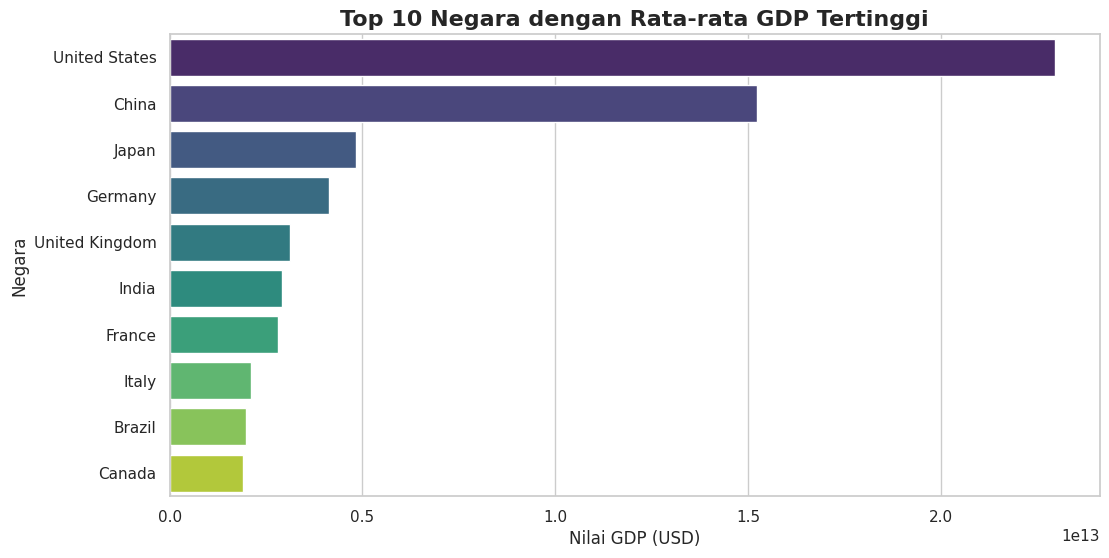

In [7]:
# Q1: 10 Negara dengan Rata-rata GDP Tertinggi
plt.figure(figsize=(12, 6))
top_gdp = df_master.groupby('country_name')['gdp_value'].mean().sort_values(ascending=False).head(10)

sns.barplot(x=top_gdp.values, y=top_gdp.index, palette='viridis')
plt.title('Top 10 Negara dengan Rata-rata GDP Tertinggi', fontsize=16, fontweight='bold')
plt.xlabel('Nilai GDP (USD)')
plt.ylabel('Negara')
plt.show()


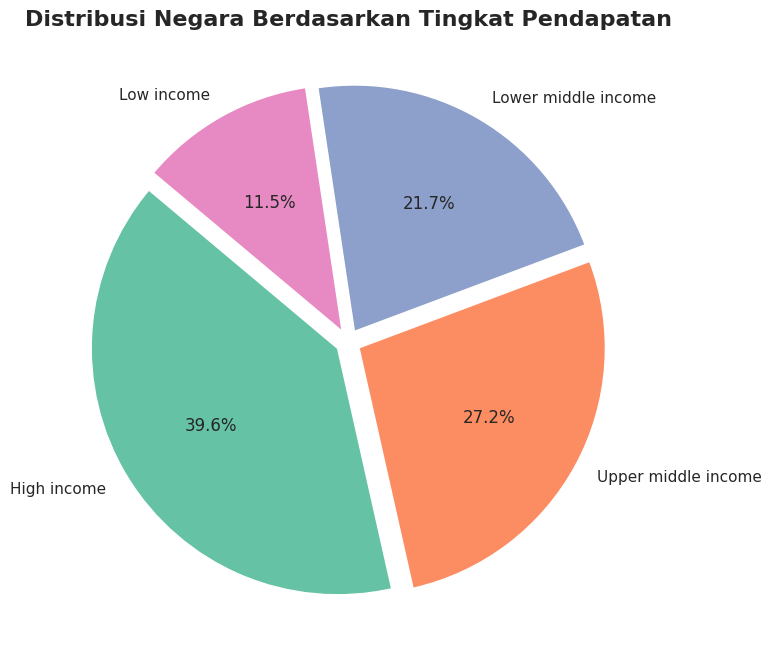

In [8]:
# Q2: Distribusi Negara berdasarkan Income Level
plt.figure(figsize=(8, 8))
income_counts = df_country_clean['income_level'].value_counts()

plt.pie(income_counts, labels=income_counts.index, autopct='%1.1f%%',
        colors=sns.color_palette("Set2"), startangle=140, explode=[0.05]*len(income_counts))
plt.title('Distribusi Negara Berdasarkan Tingkat Pendapatan', fontsize=16, fontweight='bold')
plt.show()


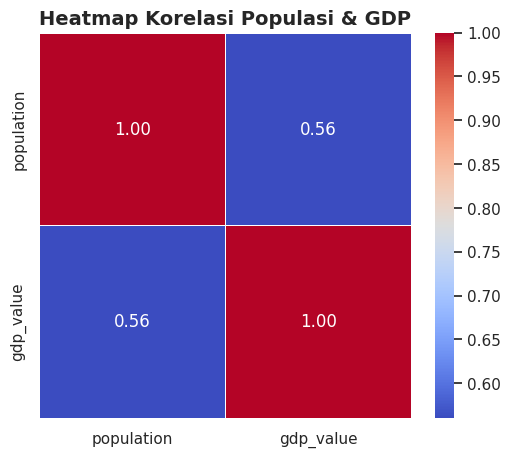

In [9]:
# Q3: Heatmap Korelasi Populasi & GDP
plt.figure(figsize=(6, 5))
correlation = df_master[['population', 'gdp_value']].corr()
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Heatmap Korelasi Populasi & GDP', fontsize=14, fontweight='bold')
plt.show()


In [10]:
# Q4: Peta Sebaran Populasi
df_latest = df_master[df_master['year'] == df_master['year'].max()]
fig = px.choropleth(
    df_latest, locations="country_code", color="population",
    hover_name="country_name", color_continuous_scale=px.colors.sequential.Plasma,
    title=f"Peta Sebaran Populasi Global ({df_master['year'].max()})"
)
fig.update_layout(geo=dict(showframe=False, showcoastlines=True, projection_type='equirectangular'))
fig.show()


## 5. Data Science & Predictive Analytics (Machine Learning)
**Menjawab Pertanyaan Bisnis ke-5:**
Kita menggunakan **Linear Regression** karena sifat data kita adalah *Time-Series* berjangka pendek (kurang dari 20 tahun data per negara). Linear Regression sangat baik untuk mengekstrapolasi tren ekonomi masa depan tanpa risiko menghafal (*Overfitting*) seperti yang sering terjadi pada algoritma berbasis *Decision Tree* (misal XGBoost) pada dataset kecil.


=== EVALUASI PERFORMA LINEAR REGRESSION ===
R-Squared (Akurasi Pola) Data Training : 92.30%
R-Squared (Akurasi Pola) Data Testing  : 68.22%

MAE (Margin Error Rata-rata) Testing   : USD 13,655,400,817.34


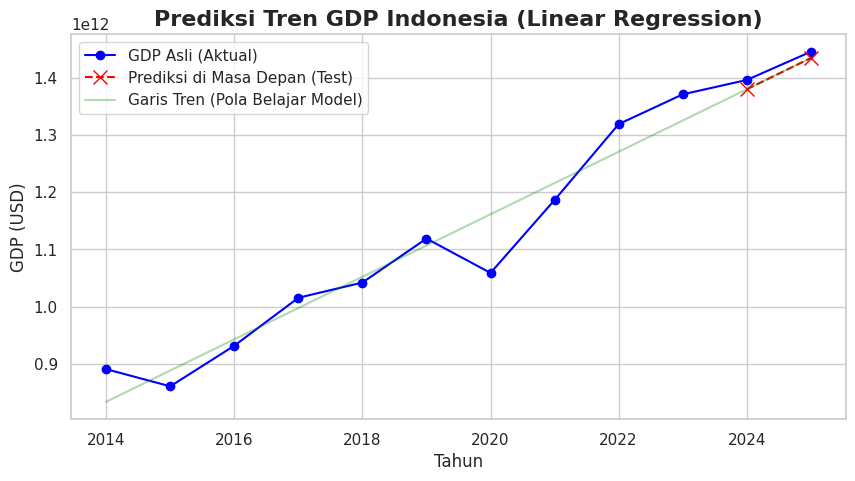

In [11]:
# Q5: Prediksi GDP (Studi Kasus: Indonesia)

# 1. Filter Data khusus Indonesia
df_ml = df_master[df_master['country_code'] == 'IDN'].sort_values('year').copy()

# 2. Persiapkan Fitur (Tahun) dan Target (GDP)
X = df_ml[['year']]
y = df_ml['gdp_value']

# 3. SPLIT DATA (2 Tahun terakhir sebagai Ujian/Testing, sisanya untuk Belajar/Training)
jumlah_test = 2

X_train = X.iloc[:-jumlah_test]
X_test  = X.iloc[-jumlah_test:]
y_train = y.iloc[:-jumlah_test]
y_test  = y.iloc[-jumlah_test:]

if len(X_train) > 0 and len(X_test) > 1:
    # 4. Training Model
    model_lr = LinearRegression()
    model_lr.fit(X_train, y_train)

    # 5. Prediksi
    y_pred_train = model_lr.predict(X_train)
    y_pred_test  = model_lr.predict(X_test)

    # 6. Evaluasi Metrics (Tanpa ada NaN karena data test > 1)
    print("=== EVALUASI PERFORMA LINEAR REGRESSION ===")
    print(f"R-Squared (Akurasi Pola) Data Training : {r2_score(y_train, y_pred_train) * 100:.2f}%")
    print(f"R-Squared (Akurasi Pola) Data Testing  : {r2_score(y_test, y_pred_test) * 100:.2f}%\n")
    print(f"MAE (Margin Error Rata-rata) Testing   : USD {mean_absolute_error(y_test, y_pred_test):,.2f}")

    # 7. Visualisasi Hasil
    plt.figure(figsize=(10, 5))

    # Plot Data Asli
    plt.plot(df_ml['year'], y, label='GDP Asli (Aktual)', marker='o', color='blue')

    # Plot Titik Prediksi di Data Testing
    plt.plot(X_test['year'], y_pred_test, label='Prediksi di Masa Depan (Test)', marker='x', linestyle='--', color='red', markersize=10)

    # Plot Garis Tarikan Model dari awal hingga akhir (Untuk melihat Tren)
    garis_tren = model_lr.predict(X)
    plt.plot(df_ml['year'], garis_tren, label='Garis Tren (Pola Belajar Model)', color='green', alpha=0.3)

    plt.title('Prediksi Tren GDP Indonesia (Linear Regression)', fontsize=16, fontweight='bold')
    plt.xlabel('Tahun')
    plt.ylabel('GDP (USD)')
    plt.legend()
    plt.grid(True)
    plt.show()

else:
    print("Data tidak cukup. Pastikan Anda punya minimal 4 tahun data histori.")


=== PROYEKSI GDP MASA DEPAN (Indonesia) ===
Tahun 2026: Prediksi GDP = USD 1,497,599,823,872.66
Tahun 2027: Prediksi GDP = USD 1,553,149,623,490.28



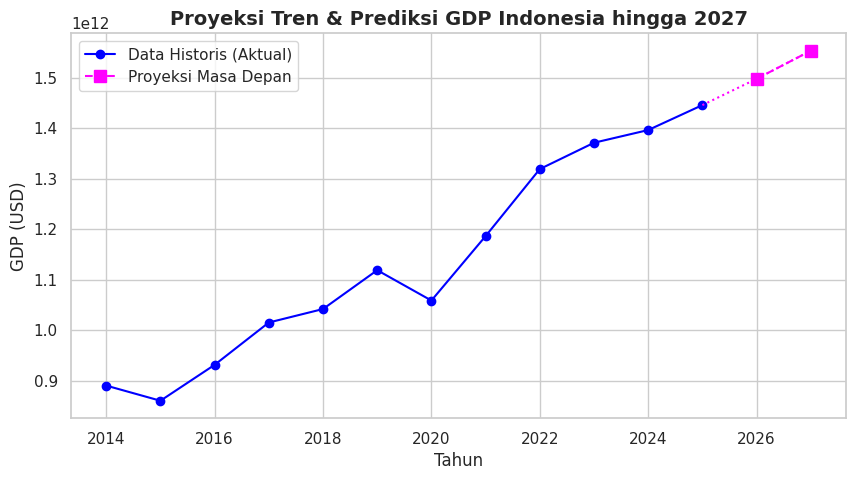

--------------------------------------------------------------------------------



In [12]:


def predict_future_gdp(country_code, country_name, future_years=[2026, 2027]):
    # 1. Filter data historis
    df_country = df_master[df_master['country_code'] == country_code].sort_values('year').copy()

    if len(df_country) < 2:
        print(f"❌ Data tidak cukup untuk {country_name}")
        return

    # 2. Fit model pada seluruh data historis yang tersedia
    X_hist = df_country[['year']]
    y_hist = df_country['gdp_value']

    model = LinearRegression()
    model.fit(X_hist, y_hist)

    # 3. Buat dataframe untuk tahun masa depan
    X_future = pd.DataFrame({'year': future_years})
    y_future_pred = model.predict(X_future)

    # 4. Tampilkan hasil prediksi dalam tabel kecil
    print(f"=== PROYEKSI GDP MASA DEPAN ({country_name}) ===")
    for yr, val in zip(future_years, y_future_pred):
        print(f"Tahun {yr}: Prediksi GDP = USD {val:,.2f}")
    print()

    # 5. Visualisasi
    plt.figure(figsize=(10, 5))
    plt.plot(df_country['year'], df_country['gdp_value'], label='Data Historis (Aktual)', marker='o', color='blue')

    # Plot titik masa depan
    plt.plot(X_future['year'], y_future_pred, label='Proyeksi Masa Depan', marker='s', linestyle='--', color='magenta', markersize=8)

    # Gabungkan garis visualisasi dari historis terakhir ke masa depan
    last_year = df_country['year'].iloc[-1]
    last_val = df_country['gdp_value'].iloc[-1]
    plt.plot([last_year] + list(X_future['year']), [last_val] + list(y_future_pred), color='magenta', linestyle=':')

    plt.title(f'Proyeksi Tren & Prediksi GDP {country_name} hingga {max(future_years)}', fontsize=14, fontweight='bold')
    plt.xlabel('Tahun')
    plt.ylabel('GDP (USD)')
    plt.legend()
    plt.grid(True)
    plt.show()
    print("-"*80 + "\n")

# Lakukan proyeksi untuk Indonesia, USA, Rusia, dan China
negara_proyeksi = [
    {'code': 'IDN', 'name': 'Indonesia'},

]

for n in negara_proyeksi:
    predict_future_gdp(n['code'], n['name'], future_years=[2026, 2027])